# 국적별 스펙트로그램 비교 — 같은 낭독 문장

AIHub '외국인 한국어 발화 음성'에는 **여러 국적 화자가 읽은 동일 낭독 문장**(`ReadingLabelText`)이 있습니다.
같은 문장을 국적(모국어)별로 골라 **로그 스펙트로그램**을 나란히 그려 억양·발음 차이를 눈으로 비교합니다.

- 매칭 키: `data/reading_index.csv` (사전 생성, 낭독 발화 80만개)
- 오디오: `baseline_common.build_audio_index` 로 fileName→경로 해석
- **Cell 5의 `TARGET_TEXT`, `NATIONS` 만 바꾸면** 됩니다.

In [1]:
import os, sys
import numpy as np
import pandas as pd
import soundfile as sf
from scipy import signal
import matplotlib.pyplot as plt
import matplotlib.font_manager as fm

sys.path.insert(0, "$HOME/scripts")
import baseline_common as bc

FONT = "$NATIONALITY_OUTPUTS/fonts/NotoSansKR.ttf"
fm.fontManager.addfont(FONT)
plt.rcParams["font.family"] = fm.FontProperties(fname=FONT).get_name()
plt.rcParams["axes.unicode_minus"] = False

SR = 16000
READING_CSV = "$NATIONALITY_DATA/reading_index.csv"
print("ready")

ready


In [2]:
ridx = pd.read_csv(READING_CSV)
print(f"낭독 발화 {len(ridx):,}개, 국적(모국어) {ridx.mother_tongue.nunique()}종")

shared = (ridx.groupby("reading_text")["mother_tongue"]
            .nunique().sort_values(ascending=False))
print("\n=== 국적 수가 많은 공유 문장 top 10 ===")
for i,(txt,n) in enumerate(shared.head(10).items()):
    print(f"[{i}] {n}개 국적 | {txt[:55]}")

낭독 발화 809,928개, 국적(모국어) 61종

=== 국적 수가 많은 공유 문장 top 10 ===
[0] 44개 국적 | 기차를 탈 때 기차표를 누구한테 보여 줘야 해요 아니면 타기 전에 무인 기계에 찍고 타나요
[1] 43개 국적 | 치맥은 치킨과 맥주의 줄임말로 한국 사람들이 즐겨 먹는 음식이다 또한 치콜 치밥이라는 것도 있다
[2] 43개 국적 | 한국 사람들은 집에서뿐만 아니라 야구장이나 한강 같은 야외에서도 치킨을 시켜 먹기도 한다
[3] 42개 국적 | 그럼 제일 빠른 케이티엑스를 타야겠어요 제가 일이 좀 바빠서요 근데 케이티엑스 표는 얼마인가요
[4] 42개 국적 | 응 치마도 이번에 새로 산 건데 정말 예쁘지 않아 우리 언니랑 지난주 일요일에 백화점에 갔다가 샀어
[5] 42개 국적 | 네 손님 우선 어느 기차를 타고 싶으세요 우리 역에는 케이티엑스와 새마을호 무궁화호 이렇게 기차 세
[6] 42개 국적 | 제가 한국에서 기차 타는 게 이번이 처음이라 잘 모르겠어요 기차 세 가지가 어떻게 다른가요
[7] 42개 국적 | 한 벌만 사도 충분한데 내가 또 과소비를 한 것 같아서 지금 생각해 보니 조금 후회가 많이 돼
[8] 42개 국적 | 의사 선생님 저는 운동을 하다가 발목을 삐었는데 걸을 때마다 아직도 아파요 사진을 찍어 볼까요
[9] 42개 국적 | 그러면 두 시 기차로 예약해 주세요 이왕이면 창가 자리면 좋겠어요 근데 오늘 왜 이렇게 자리가 없나


In [3]:
print("오디오 인덱스 빌드 중...")
audio_idx = bc.build_audio_index(bc.DEFAULT_AUDIO_ROOT)
print(f"wav {len(audio_idx):,}개 인덱싱됨")

오디오 인덱스 빌드 중...
wav 1,042,269개 인덱싱됨


In [4]:
# ===== 여기만 바꾸면 됨 =====
TARGET_TEXT = shared.index[0]
NATIONS = ["중국어","일본어","베트남어","태국어","몽골어","러시아어","영어","스페인어","광동어"]
SEED = 0
# ===========================

sub = ridx[ridx.reading_text == TARGET_TEXT]
print(f"문장: {TARGET_TEXT}")
print(f"이 문장을 읽은 국적 수: {sub.mother_tongue.nunique()}")

picks = {}
for nat in NATIONS:
    cand = sub[sub.mother_tongue == nat].sample(frac=1, random_state=SEED)
    for _, r in cand.iterrows():
        p = audio_idx.get(r.fileName)
        if p and os.path.exists(p):
            picks[nat] = (r.fileName, p); break
print("\n선택된 국적:", list(picks.keys()))
miss = [n for n in NATIONS if n not in picks]
if miss: print("오디오 못 찾음(스킵):", miss)

문장: 기차를 탈 때 기차표를 누구한테 보여 줘야 해요 아니면 타기 전에 무인 기계에 찍고 타나요
이 문장을 읽은 국적 수: 44

선택된 국적: ['중국어', '일본어', '베트남어', '태국어', '몽골어', '러시아어', '영어', '스페인어', '광동어']


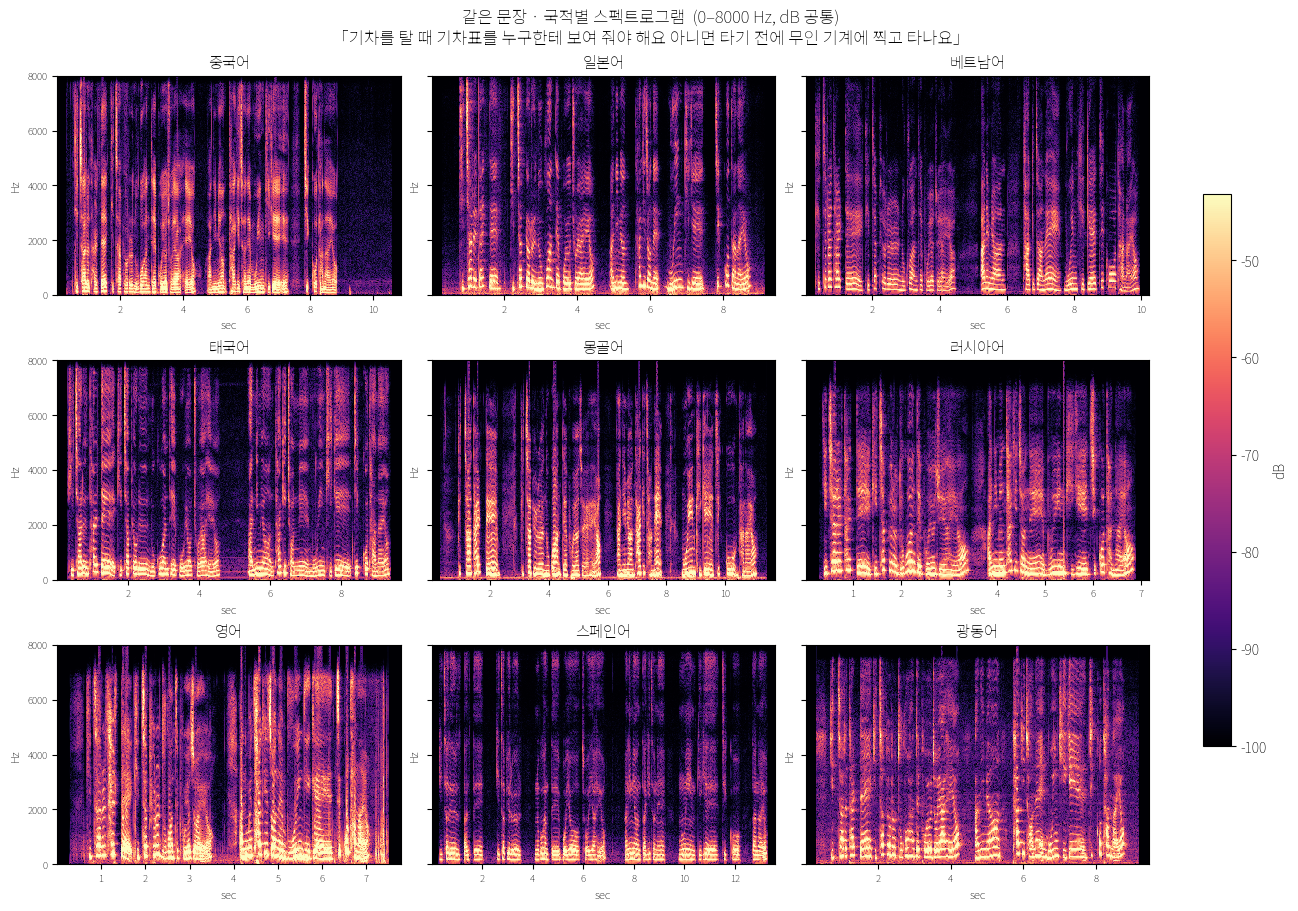

In [5]:
def load_wav(path, sr=SR):
    y, s = sf.read(path)
    if y.ndim > 1: y = y.mean(axis=1)
    y = y.astype(np.float32)
    if s != sr:
        from math import gcd
        from scipy.signal import resample_poly
        g = gcd(int(s), sr); y = resample_poly(y, sr//g, int(s)//g)
    return y

def log_spectrogram(y, sr=SR, nperseg=512, noverlap=384, fmax=8000):
    f, t, Sxx = signal.spectrogram(y, fs=sr, nperseg=nperseg, noverlap=noverlap)
    S = 10*np.log10(Sxx + 1e-10)
    m = f <= fmax
    return t, f[m], S[m]

FMAX = 8000                       # 주파수 축 상한(Hz) — 모든 국적 공통
specs = {nat: log_spectrogram(load_wav(p)) for nat,(fn,p) in picks.items()}

# 모든 국적 공통 dB 색범위 → 색까지 직접 비교 가능
allS = np.concatenate([S.ravel() for _,_,S in specs.values()])
vmin, vmax = np.percentile(allS, 5), np.percentile(allS, 99)

n = len(specs); cols = 3; rows = (n + cols - 1)//cols
fig, axes = plt.subplots(rows, cols, figsize=(cols*4.3, rows*3.0),
                         squeeze=False, sharey=True, constrained_layout=True)
for ax in axes.flat: ax.axis("off")
im = None
for ax, (nat,(t,f,S)) in zip(axes.flat, specs.items()):
    ax.axis("on")
    im = ax.pcolormesh(t, f, S, shading="auto", cmap="magma", vmin=vmin, vmax=vmax)
    ax.set_ylim(0, FMAX)                      # Hz 축 고정
    ax.set_yticks(np.arange(0, FMAX+1, 2000)) # 0,2k,4k,6k,8k 공통 눈금
    ax.set_title(nat, fontsize=11)
    ax.set_xlabel("sec", fontsize=8); ax.set_ylabel("Hz", fontsize=8)
    ax.tick_params(labelsize=7)
fig.colorbar(im, ax=axes, shrink=0.7, label="dB")   # 공통 컬러바
fig.suptitle(f"같은 문장 · 국적별 스펙트로그램  (0–{FMAX} Hz, dB 공통)\n「{TARGET_TEXT}」", fontsize=12)
plt.show()

## 🔊 국적별 음성 듣기 (같은 문장)

In [6]:
from IPython.display import display, Audio, HTML

for nat, (fn, p) in picks.items():
    y = load_wav(p)
    display(HTML(f"<b style='font-size:15px'>{nat}</b> &nbsp; "
                 f"<span style='color:#888'>{fn} · {len(y)/SR:.1f}s</span>"))
    display(Audio(y, rate=SR))

## 📊 국적별 평균 분석 (화자 여러 명 평균 → 화자 영향 제거)

같은 문장 1명 비교는 화자 목소리에 좌우됩니다. 국적당 **서로 다른 화자 N명**을 모아 평균하면 사람마다 다른 건 씻기고 **국적 공통 신호**만 남습니다.
- **LTAS**: 국적별 장기 평균 스펙트럼(주파수대 에너지) 겹쳐 그리기
- **F0 / F1 / F2 박스플롯 + 모음공간**: 피치·모음 위치가 국적별로 갈리는지 (parselmouth/Praat)

In [7]:
import parselmouth as pm

ANALYSIS_NATIONS = ["중국어","일본어","베트남어","태국어","몽골어","러시아어","영어","미얀마어"]
N_SPK  = 20      # 국적당 서로 다른 화자 수
MAXSEC = 12

def _sample_spk_utts(nat, n, seed=0):
    d = ridx[ridx.mother_tongue==nat].sample(frac=1, random_state=seed)
    seen=set(); out=[]
    for _, r in d.iterrows():
        if r.speaker_id in seen: continue
        p = audio_idx.get(r.fileName)
        if p and os.path.exists(p):
            out.append(p); seen.add(r.speaker_id)
        if len(out) >= n: break
    return out

def _ltas(y, sr=SR):
    f, P = signal.welch(y, fs=sr, nperseg=512)
    S = 10*np.log10(P + 1e-12)
    return f, S - S.mean()           # 평균 제거 → 모양만 비교(라우드니스 무관)

def _f0_formants(path):
    snd = pm.Sound(path)
    if snd.duration > MAXSEC: snd = snd.extract_part(0, MAXSEC)
    pitch = snd.to_pitch(); f0 = pitch.selected_array["frequency"]; ts = pitch.xs(); v = f0 > 0
    form = snd.to_formant_burg(maximum_formant=5500)
    f1=[]; f2=[]
    for t in ts[v]:
        a = form.get_value_at_time(1, t); b = form.get_value_at_time(2, t)
        if a and b and not np.isnan(a) and not np.isnan(b): f1.append(a); f2.append(b)
    return (np.median(f0[v]) if v.any() else np.nan,
            np.median(f1) if f1 else np.nan,
            np.median(f2) if f2 else np.nan)

ltas_by = {}
feats = {n: {"f0": [], "f1": [], "f2": []} for n in ANALYSIS_NATIONS}
for nat in ANALYSIS_NATIONS:
    paths = _sample_spk_utts(nat, N_SPK); curves = []
    for p in paths:
        y, s = sf.read(p)
        if y.ndim > 1: y = y.mean(1)
        y = y[:int(MAXSEC*SR)].astype(np.float32)
        f, S = _ltas(y); curves.append(S)
        a, b, c = _f0_formants(p)
        if not np.isnan(a): feats[nat]["f0"].append(a)
        if not np.isnan(b): feats[nat]["f1"].append(b); feats[nat]["f2"].append(c)
    ltas_by[nat] = (f, np.mean(curves, axis=0))
    print(f"{nat}: {len(paths)}명  F0~{np.median(feats[nat]['f0']):.0f}  "
          f"F1~{np.median(feats[nat]['f1']):.0f}  F2~{np.median(feats[nat]['f2']):.0f}", flush=True)
print("done")

중국어: 20명  F0~199  F1~444  F2~1619
일본어: 20명  F0~209  F1~504  F2~1647
베트남어: 20명  F0~217  F1~455  F2~1682
태국어: 20명  F0~216  F1~468  F2~1724
몽골어: 20명  F0~191  F1~469  F2~1697
러시아어: 20명  F0~214  F1~456  F2~1650
영어: 20명  F0~188  F1~451  F2~1618
미얀마어: 20명  F0~215  F1~500  F2~1660
done


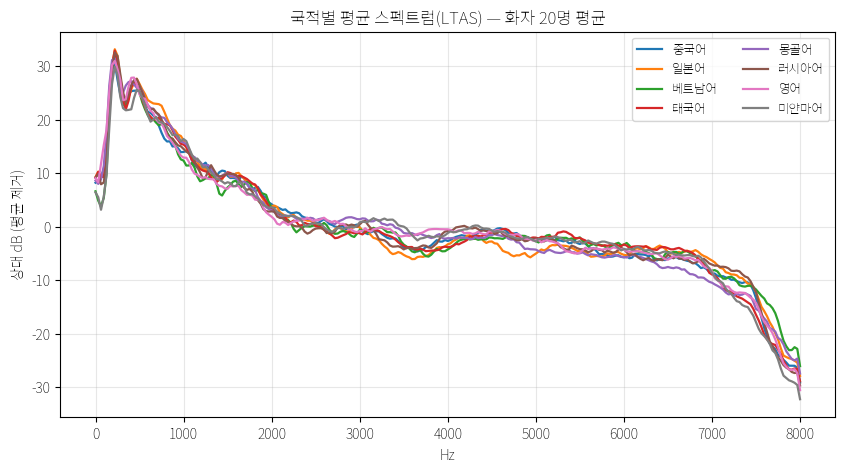

In [8]:
fig, ax = plt.subplots(figsize=(10,5))
for nat,(f,S) in ltas_by.items():
    m = f <= 8000; ax.plot(f[m], S[m], label=nat, lw=1.6)
ax.set_xlabel("Hz"); ax.set_ylabel("상대 dB (평균 제거)")
ax.set_title(f"국적별 평균 스펙트럼(LTAS) — 화자 {N_SPK}명 평균")
ax.legend(ncol=2, fontsize=9); ax.grid(alpha=.3)
plt.show()

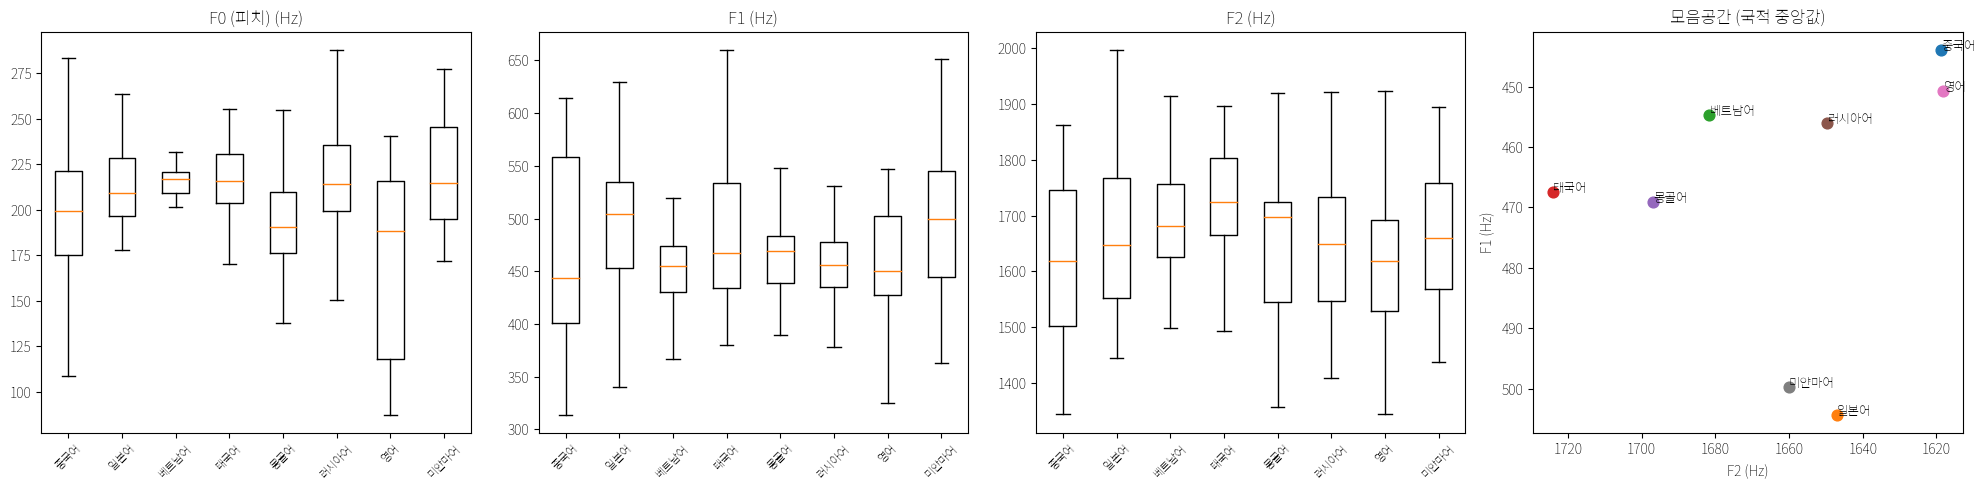

In [9]:
fig, axs = plt.subplots(1, 4, figsize=(20,5))
for ax, key, ttl in zip(axs[:3], ["f0","f1","f2"], ["F0 (피치)","F1","F2"]):
    ax.boxplot([feats[n][key] for n in ANALYSIS_NATIONS], labels=ANALYSIS_NATIONS, showfliers=False)
    ax.set_title(ttl + " (Hz)"); ax.tick_params(axis="x", rotation=45, labelsize=8)
ax = axs[3]
for n in ANALYSIS_NATIONS:
    x, y = np.median(feats[n]["f2"]), np.median(feats[n]["f1"])
    ax.scatter(x, y, s=60); ax.annotate(n, (x, y), fontsize=9)
ax.invert_xaxis(); ax.invert_yaxis()
ax.set_xlabel("F2 (Hz)"); ax.set_ylabel("F1 (Hz)"); ax.set_title("모음공간 (국적 중앙값)")
plt.tight_layout(); plt.show()

## 사용법
- **다른 문장**: Cell 3 출력 `[i] N개 국적 | ...` 보고 Cell 5에서 `TARGET_TEXT = shared.index[i]`.
- **다른 국적**: Cell 5 `NATIONS` 수정 (모국어 이름: 우즈베크어/미얀마어/터키어 등).
- **멜 스펙트로그램**: `log_spectrogram`을 멜 필터뱅크로 교체(또는 librosa 설치).